Датасет про сорты Бобов

https://www.kaggle.com/datasets/sansuthi/dry-bean-dataset?select=Dry_Bean.csv

Информация об атрибутах:

* Площадь (A): площадь фасолины и количество пикселей в ее границах.
* Периметр (P): окружность фасолины определяется как длина ее границы.
* Длина большой оси (L): расстояние между концами самой длинной линии, которую можно провести от фасолины.
* Длина малой оси (l): самая длинная линия, которую можно провести от фасолины, перпендикулярно главной оси.
* Соотношение сторон (K): определяет соотношение между L и l.
* Эксцентриситет (Ec): эксцентриситет эллипса, имеющего те же моменты, что и исследуемая область.
* Выпуклая область (C): количество пикселей в наименьшем выпуклом многоугольнике, который может вместить площадь семени фасоли.
* Эквивалентный диаметр (Ed): диаметр круга, площадь которого равна площади семени фасоли.
* Экстент (Ex): отношение количества пикселей в ограничительной рамке к площади семени фасоли.
* Плотность (S): также известна как выпуклость. Отношение количества пикселей в выпуклой оболочке к количеству пикселей в бобах.
* Округлость (R): рассчитывается по следующей формуле: (4piA)/(P^2)
* Компактность (CO): измеряет округлость объекта: Ed/L
* ShapeFactor1 (SF1)
* ShapeFactor2 (SF2)
* ShapeFactor3 (SF3)
* ShapeFactor4 (SF4)

Целевая переменная: класс (Seker, Barbunya, Bombay, Cali, Dermosan, Horoz и Sira)

# Задача: Отобразить высокомерные данные $X ∈ ℝ^D$ в низкомерное пространство $Y ∈ ℝ^d (d=2,3)$ так, чтобы сохранить структуру соседства.

    1. Вероятностная постановка задачи


Задача: Отобразить высокомерные данные X ∈ ℝ^D в низкомерное пространство Y ∈ ℝ^d (d=2,3) 
так, чтобы сохранить структуру соседства.


        - Вероятности в исходном пространстве

Гауссово ядро для измерения сходства:

$
p_{j|i} = exp(-||x_i - x_j||^2 / (2σ_i^2)) / Σ_{k≠i} exp(-||x_i - x_k||^2 / (2σ_i^2))$

Симметризация вероятностей:

$
p_{ij} = (p_{j|i} + p_{i|j}) / (2n)$

Перплексия (perplexity) как гиперпараметр:

$
Perp(P_i) = 2^{H(P_i)}, $

где $H(P_i) = -Σ_j p_{j|i} log₂ p_{j|i}$

        - Вероятности в целевом пространстве

Распределение Стьюдента с одной степенью свободы:

$
q_{ij} = (1 + ||y_i - y_j||^2)^{-1} / Σ_{k≠l} (1 + ||y_k - y_l||^2)^{-1}$

Преимущества t-распределения:

       * Тяжелые хвосты

       * Устойчивость к проклятию размерности

       * Улучшенное разделение кластеров

       * Функция стоимости (KL-дивергенция)
 
$C(Y) = KL(P||Q) = Σ_i Σ_j p_{ij} log(p_{ij} / q_{ij})$

    2. Оптимизация функции стоимости

        2.1. Градиент функции стоимости

$∂C/∂y_i = 4 Σ_j (p_{ij} - q_{ij})(y_i - y_j)(1 + ||y_i - y_j||^2)^{-1}$

       2.2. Методы оптимизации

Градиентный спуск с моментумом:

$Y^{(t)} = Y^{(t-1)} + η ∂C/∂Y + α(t)(Y^{(t-1)} - Y^{(t-2)})$


Раннее преувеличение (early exaggeration):

 
$p_{ij} ← p_{ij} × 4 (первые 100 итераций)$


Адаптивное обучение (adaptive learning rate)

        2.3. Сложности оптимизации

            - Невыпуклость функции стоимости

            - Локальные минимумы

            - Чувствительность к начальной инициализации

            - Вычислительная сложность O(n²)

Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


# Задание

1. Провести исследование влияния гиперпараметров на результаты кластеризации с T-SNE
2. Сравнить с PCA 
   
Использовать 2 датасета - стандартного типа Ирис или Цифры, и своего. Не забываем про нормировку и eda в целом

In [2]:
# путь к вашему файлу
path = "Dry_Bean.csv"  # замените на реальный путь

df = pd.read_csv(path)
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Ограничимся тремя классами: 'HOROZ', 'SEKER', 'CALI'

In [3]:
df = df[df['Class'].isin(['HOROZ', 'SEKER', 'CALI'])]

In [4]:
class_names = {
    0: 'HOROZ',
    1: 'SEKER',
    2: 'CALI'
}

names = {v: k for k, v in class_names.items()}
df['Class'] = df['Class'].map(names)
df

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,1
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,1
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,1
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,1
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7424,74456,1085.466,447.665972,212.382328,2.107831,0.880298,75096,307.896612,0.788821,0.991478,0.794104,0.687782,0.006012,0.000830,0.473044,0.997097,0
7425,74509,1092.049,456.758154,208.709798,2.188484,0.889499,75260,308.006177,0.797314,0.990021,0.785117,0.674331,0.006130,0.000782,0.454722,0.995153,0
7426,75402,1086.551,448.285753,217.165372,2.064260,0.874827,76439,309.846427,0.784335,0.986434,0.802588,0.691181,0.005945,0.000837,0.477731,0.986160,0
7427,75675,1106.158,452.664524,213.509218,2.120117,0.881774,76468,310.406834,0.612852,0.989630,0.777191,0.685733,0.005982,0.000816,0.470229,0.996941,0


In [20]:
df.info()

<class 'pandas.DataFrame'>
Index: 5585 entries, 0 to 7428
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             5585 non-null   int64  
 1   Perimeter        5585 non-null   float64
 2   MajorAxisLength  5585 non-null   float64
 3   MinorAxisLength  5585 non-null   float64
 4   AspectRation     5585 non-null   float64
 5   Eccentricity     5585 non-null   float64
 6   ConvexArea       5585 non-null   int64  
 7   EquivDiameter    5585 non-null   float64
 8   Extent           5585 non-null   float64
 9   Solidity         5585 non-null   float64
 10  roundness        5585 non-null   float64
 11  Compactness      5585 non-null   float64
 12  ShapeFactor1     5585 non-null   float64
 13  ShapeFactor2     5585 non-null   float64
 14  ShapeFactor3     5585 non-null   float64
 15  ShapeFactor4     5585 non-null   float64
 16  Class            5585 non-null   int64  
dtypes: float64(14), int64(3)
memor

Пропуски отсутствуют, все признаки числовые

In [22]:
print("Количество образцов по классам:")
print(df['Class'].value_counts().sort_index())

Количество образцов по классам:
Class
0    1928
1    2027
2    1630
Name: count, dtype: int64


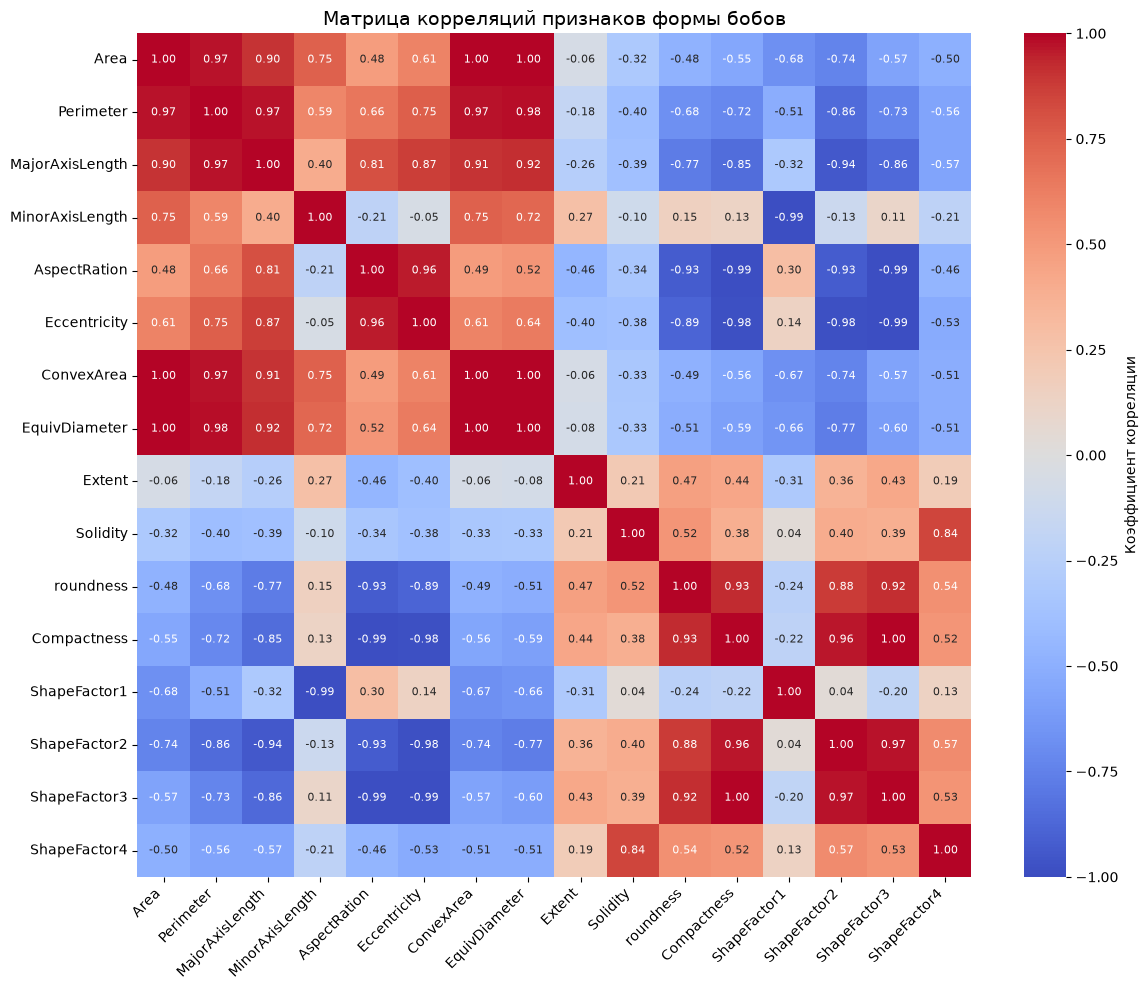

In [23]:
plt.figure(figsize=(12, 10))
corr_matrix = df.drop(columns=['Class']).corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', 
            cbar_kws={'label': 'Коэффициент корреляции'}, vmin=-1, vmax=1,
            annot_kws={"size": 8})
plt.title('Матрица корреляций признаков формы бобов', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Два крупных блока сильно коррелирующих признаков:
1. Area, Perimeter, MajorAxisLength, ConvexArea, EquivDiameter (отвечают за размер)
2. roundness, Compactness, ShapeFactor2, ShapeFactor3 (отвечают за форму)

Но есть и слабо коррелирующие признаки (например, Extent, Solidity)

In [24]:
from sklearn.datasets import load_digits

# 1. Загрузка данных
digits = load_digits()
X = digits.data
y = digits.target

Разделить выборку на фичи и целевую переменную

In [25]:
feature_cols = 'Class'
X_db = df.drop(feature_cols, axis=1).to_numpy()
y_db = df[feature_cols].to_numpy()

y_names = [class_names[n] for n in y_db]

print(X_db.shape, y_db.shape)

(5585, 16) (5585,)


Нормировка

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_db_scaled = scaler.fit_transform(X_db)

pca = PCA(n_components=2, random_state=42)

PCA: Digits
Доля объяснённой дисперсии: [0.12033916 0.09561054] 
Суммарно: 0.21594970500832794


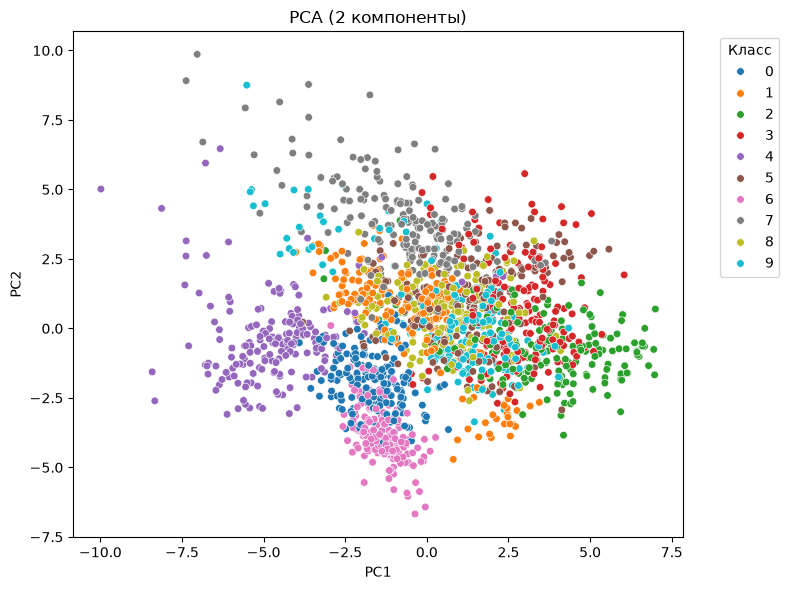

In [27]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("PCA: Digits")
print("Доля объяснённой дисперсии:",  pca.explained_variance_ratio_ ,
      "\nСуммарно:", sum(pca.explained_variance_ratio_) )

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette="tab10", s=30)
plt.title("PCA (2 компоненты)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

PCA: Dry_Bean
Доля объяснённой дисперсии: [0.61492496 0.24030588] 
Суммарно: 0.8552308448968928


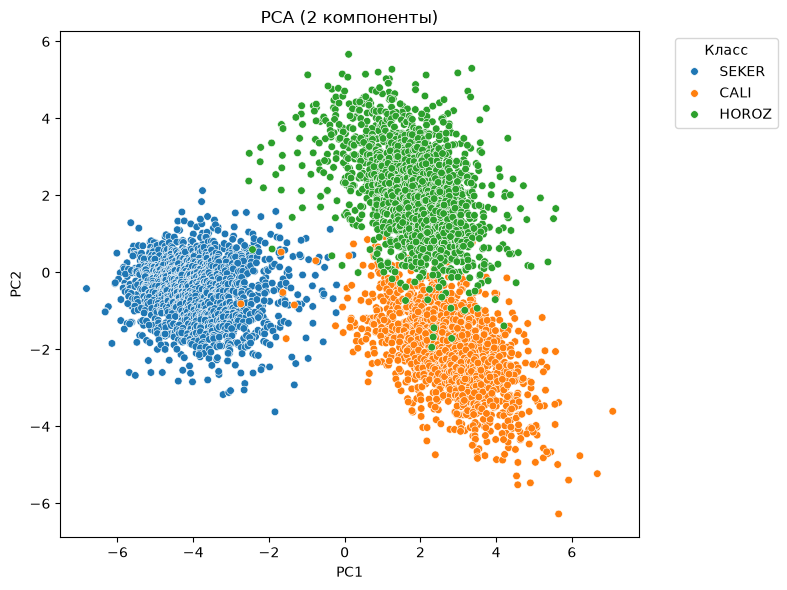

In [29]:
pca = PCA(n_components=2, random_state=42)
X_db_pca = pca.fit_transform(X_db_scaled)
print("PCA: Dry_Bean")
print("Доля объяснённой дисперсии:",  pca.explained_variance_ratio_ ,
      "\nСуммарно:", sum(pca.explained_variance_ratio_) )

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_db_pca[:, 0], y=X_db_pca[:, 1], hue=y_names, palette="tab10", s=30)
plt.title("PCA (2 компоненты)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


TSNE 2 компоненты

t-SNE: Digits


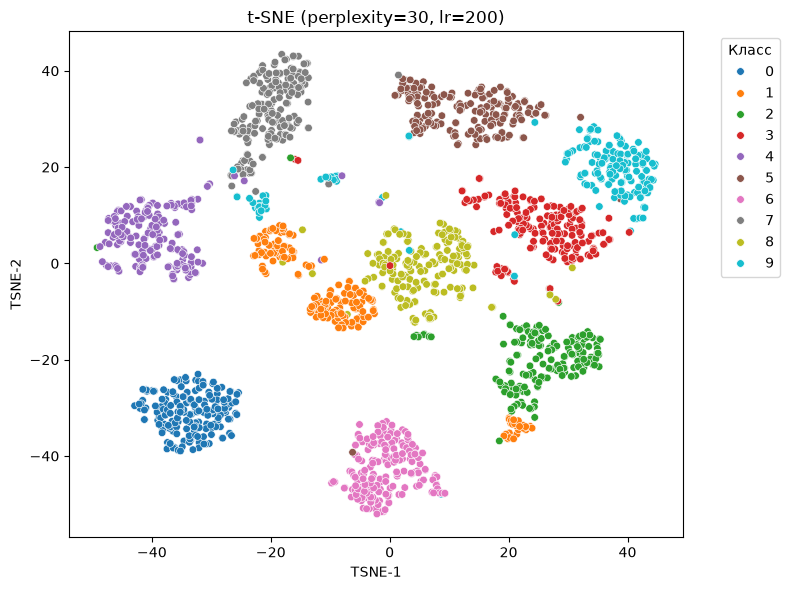

In [30]:
print("t-SNE: Digits")

tsne = TSNE(
    n_components=2,
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette="tab10", s=30)
plt.title("t-SNE (perplexity=30, lr=200)")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


t-SNE: Dry_Bean


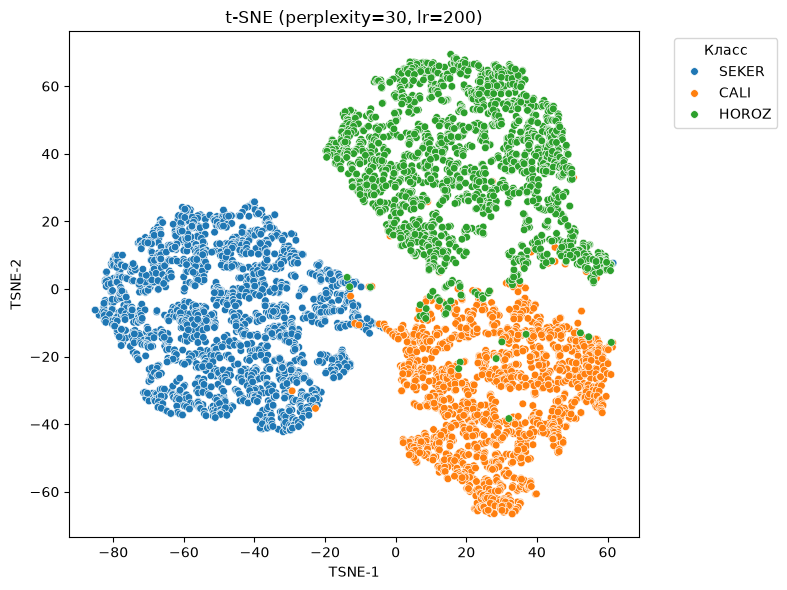

In [31]:
print("t-SNE: Dry_Bean")

tsne = TSNE(
    n_components=2,
    random_state=42
)

X_db_tsne = tsne.fit_transform(X_db_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_db_tsne[:, 0], y=X_db_tsne[:, 1], hue=y_names, palette="tab10", s=30)
plt.title("t-SNE (perplexity=30, lr=200)")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.metrics import pairwise_distances

def separation_score(X_2d, y):
    D = pairwise_distances(X_2d)
    same = D[y[:, None] == y[None, :]]
    diff = D[y[:, None] != y[None, :]]
    return same.mean(), diff.mean(), diff.mean() / same.mean()

print("Digits")
pca_same, pca_diff, pca_ratio = separation_score(X_pca, y)
tsne_same, tsne_diff, tsne_ratio = separation_score(X_tsne, y)

print("PCA:  среднее расстояние внутри класса =", pca_same,
      ", между классами =", pca_diff,
      ", ratio =", pca_ratio)
print("t-SNE: среднее расстояние внутри класса =", tsne_same,
      ", между классами =", tsne_diff,
      ", ratio =", tsne_ratio)

print("\nDry_Bean")
pca_same, pca_diff, pca_ratio = separation_score(X_db_pca, y_db)
tsne_same, tsne_diff, tsne_ratio = separation_score(X_db_tsne, y_db)

print("PCA:  среднее расстояние внутри класса =", pca_same,
      ", между классами =", pca_diff,
      ", ratio =", pca_ratio)
print("t-SNE: среднее расстояние внутри класса =", tsne_same,
      ", между классами =", tsne_diff,
      ", ratio =", tsne_ratio)


Digits
PCA:  среднее расстояние внутри класса = 2.4682343991638227 , между классами = 4.7614561566878075 , ratio = 1.9290939945982732
t-SNE: среднее расстояние внутри класса = 12.129468 , между классами = 48.47683 , ratio = 3.9966164

Dry_Bean
PCA:  среднее расстояние внутри класса = 1.7221507400562928 , между классами = 6.008335129919237 , ratio = 3.4888555282465226
t-SNE: среднее расстояние внутри класса = 32.213444 , между классами = 79.76866 , ratio = 2.4762537


Digits:
* PCA объясняет лишь 21.6% дисперсии и плохо разделяет классы (ratio = 1.93) из-за нелинейности данных.
* t-SNE справляется значительно лучше, увеличивая отношение расстояний между классами почти в 2 раза (ratio = 3.99) и формируя 10 кластеров.

Dry Bean:
* PCA объясняет 85.5% дисперсии и обеспечивает отличное разделение (ratio = 3.49).
* t-SNE снижает метрику разделения (ratio = 2.48) по сравнению с PCA.

Вычислить и отрисовать T-SNE с разным значением Perplexity

Digits


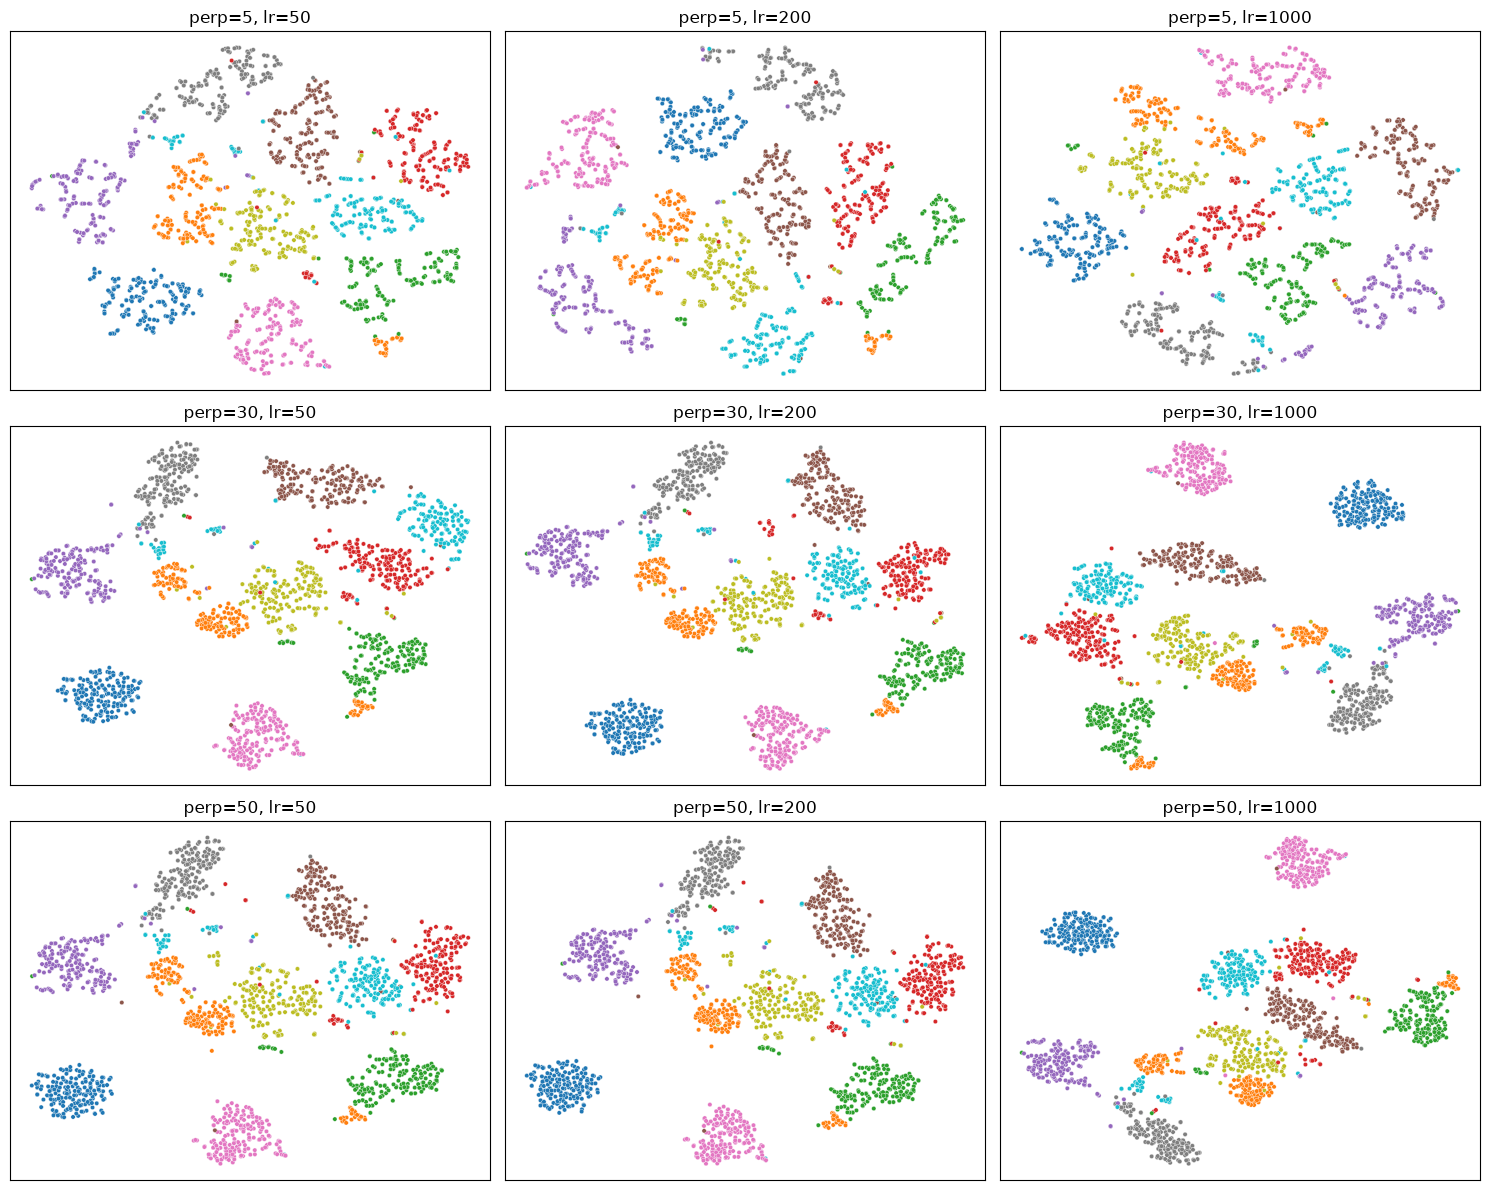

In [13]:
print("Digits")

perplexities = [5, 30, 50]
learning_rates = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(learning_rates),
                         figsize=(5*len(learning_rates), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(learning_rates):
        tsne = TSNE(
            perplexity=perp,
            learning_rate=lr,
            random_state=42            
        )
        X_emb = tsne.fit_transform(X_scaled)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1],
                        hue=y, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"perp={perp}, lr={lr}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

Датасет чувствителен к изменению параметров:
1. При увеличении perplexity кластеры становятся плотнее и компактнее. 
2. При увеличении обоих параметров кластеры меняются местами. Картина сильно меняется. Рисунок не стабилен.


Dry_Bean


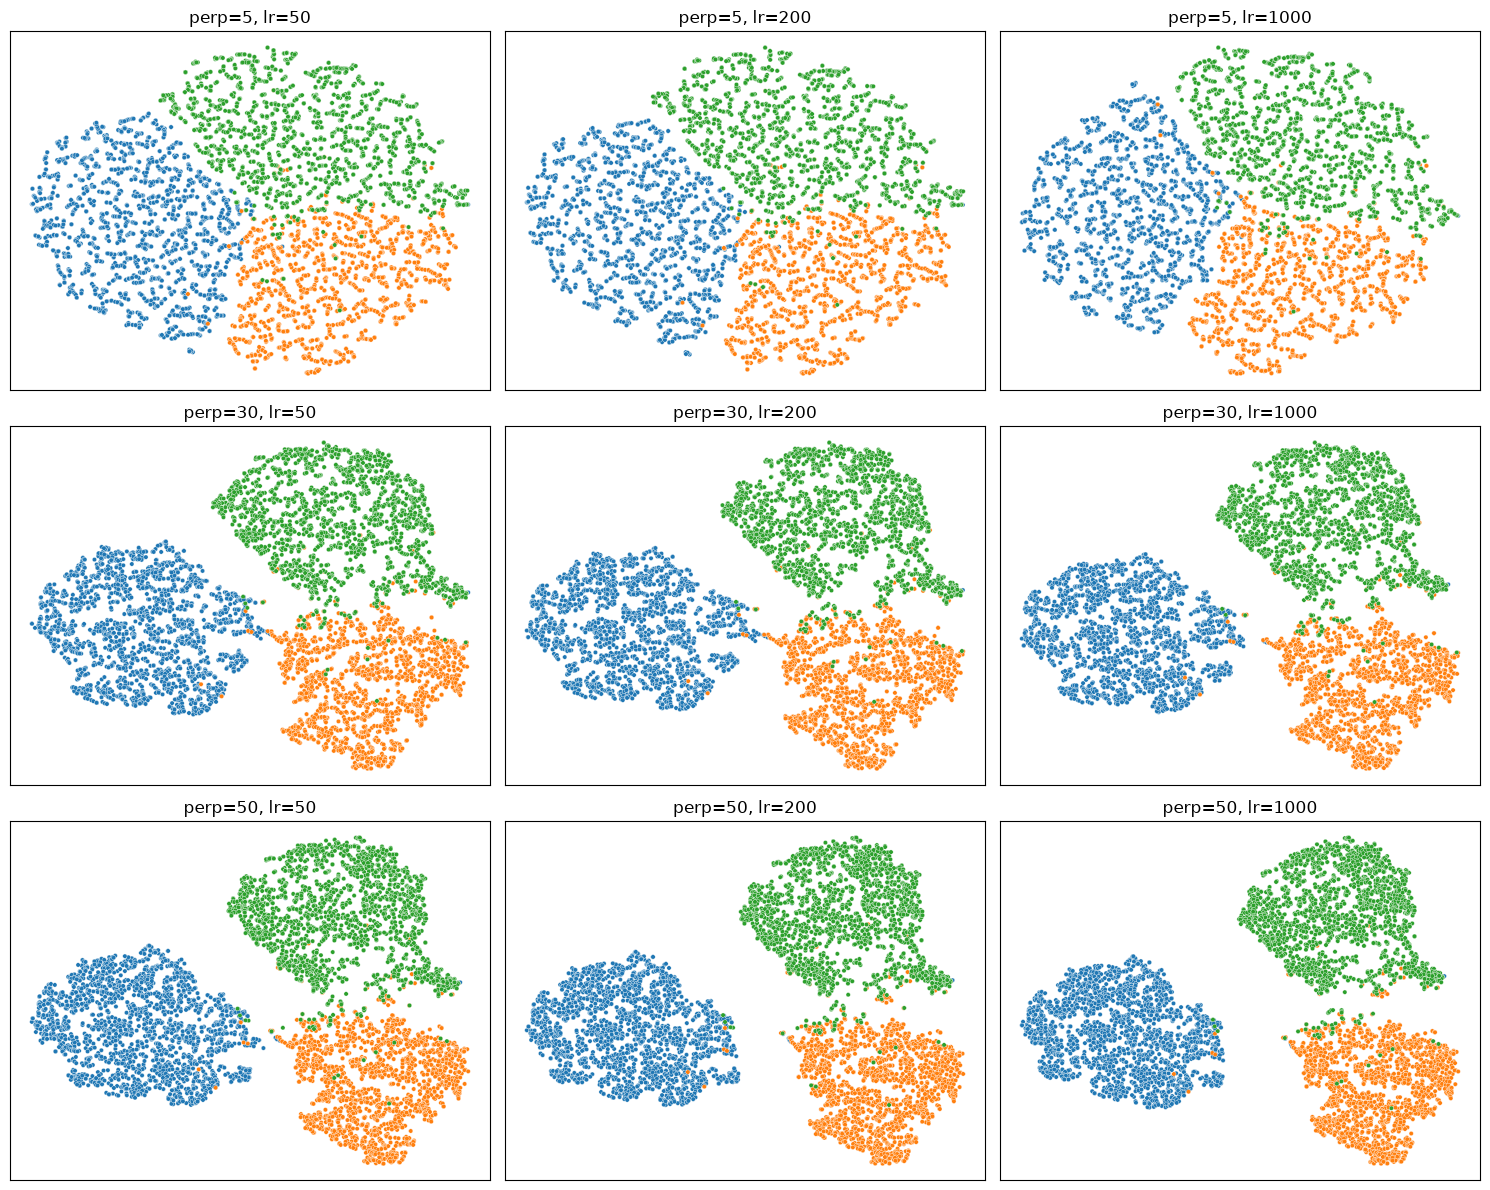

In [14]:
print("Dry_Bean")

perplexities = [5, 30, 50]
learning_rates = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(learning_rates),
                         figsize=(5*len(learning_rates), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(learning_rates):
        tsne = TSNE(
            perplexity=perp,
            learning_rate=lr,
            random_state=42            
        )
        X_db_emb = tsne.fit_transform(X_db_scaled)
        ax = axes[i, j]
        sns.scatterplot(x=X_db_emb[:, 0], y=X_db_emb[:, 1],
                        hue=y_names, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"perp={perp}, lr={lr}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

1. При увеличении learning_rate почти ничего не меняется. Заметна небольшая разница при 1000. Рисунок стабилен.
2. При увеличении perplexity кластеры становятся плотнее и компактнее. Это сразу видно при изменинии с 5 до 30. Заметно отдаляется класс SEKER.

Проанализируйте:

как меняется форма кластеров,

возникают ли “разрывы” или слияния при разных параметрах,

насколько стабилен рисунок при небольших изменениях параметров.

PCA: устойчивая структура
Для PCA параметров немного (по сути только число компонент), проекция при фиксированном random_state практически не меняется, что показывает устойчивость метода.

Можно показать, что при разных n_components (2, 3, больше) первые две компоненты остаются близкими, а общая структура мало меняется.

In [15]:
n_components = [2, 3, 4, 5, 7, 10]

Digits


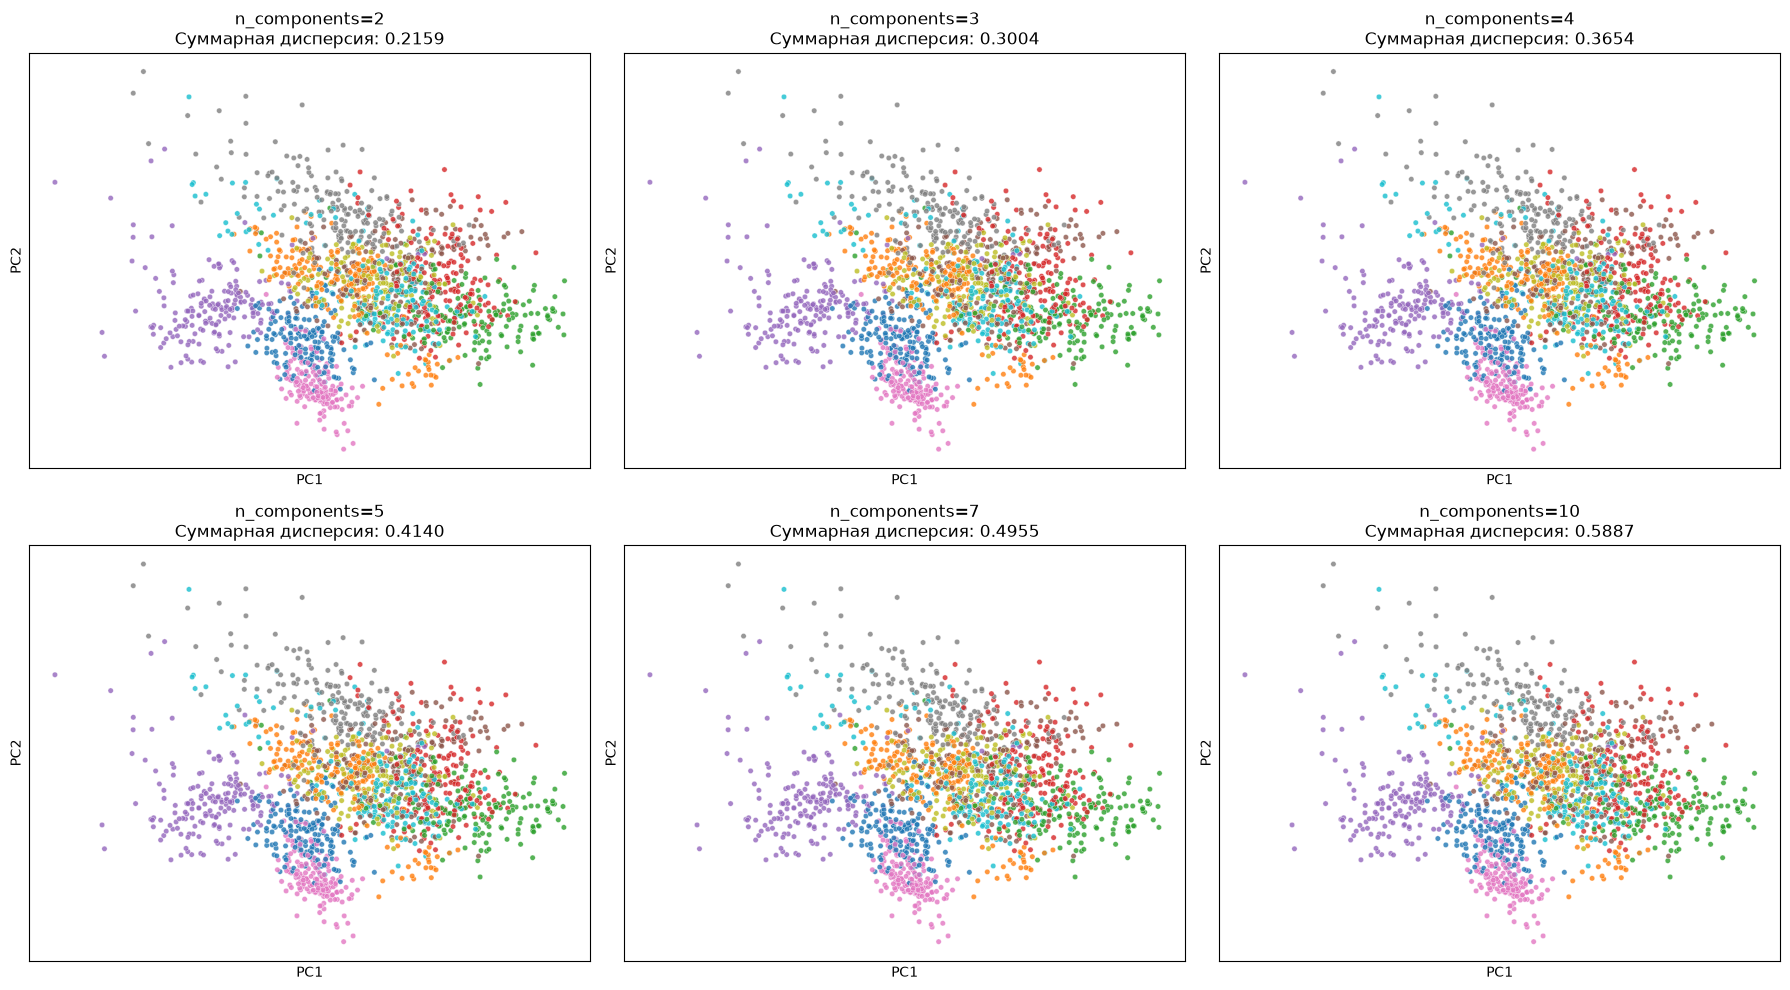

In [35]:
print("Digits")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, n in enumerate(n_components):
    pca = PCA(n_components=n, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    
    ax = axes[i]
    scatter = sns.scatterplot(
        x=X_pca[:, 0], y=X_pca[:, 1],
        hue=y, palette="tab10", s=15, ax=ax, legend=False, alpha=0.8
    )
    ax.set_title(f"n_components={n}\nСуммарная дисперсия: {pca.explained_variance_ratio_.sum():.4f}", fontsize=12)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

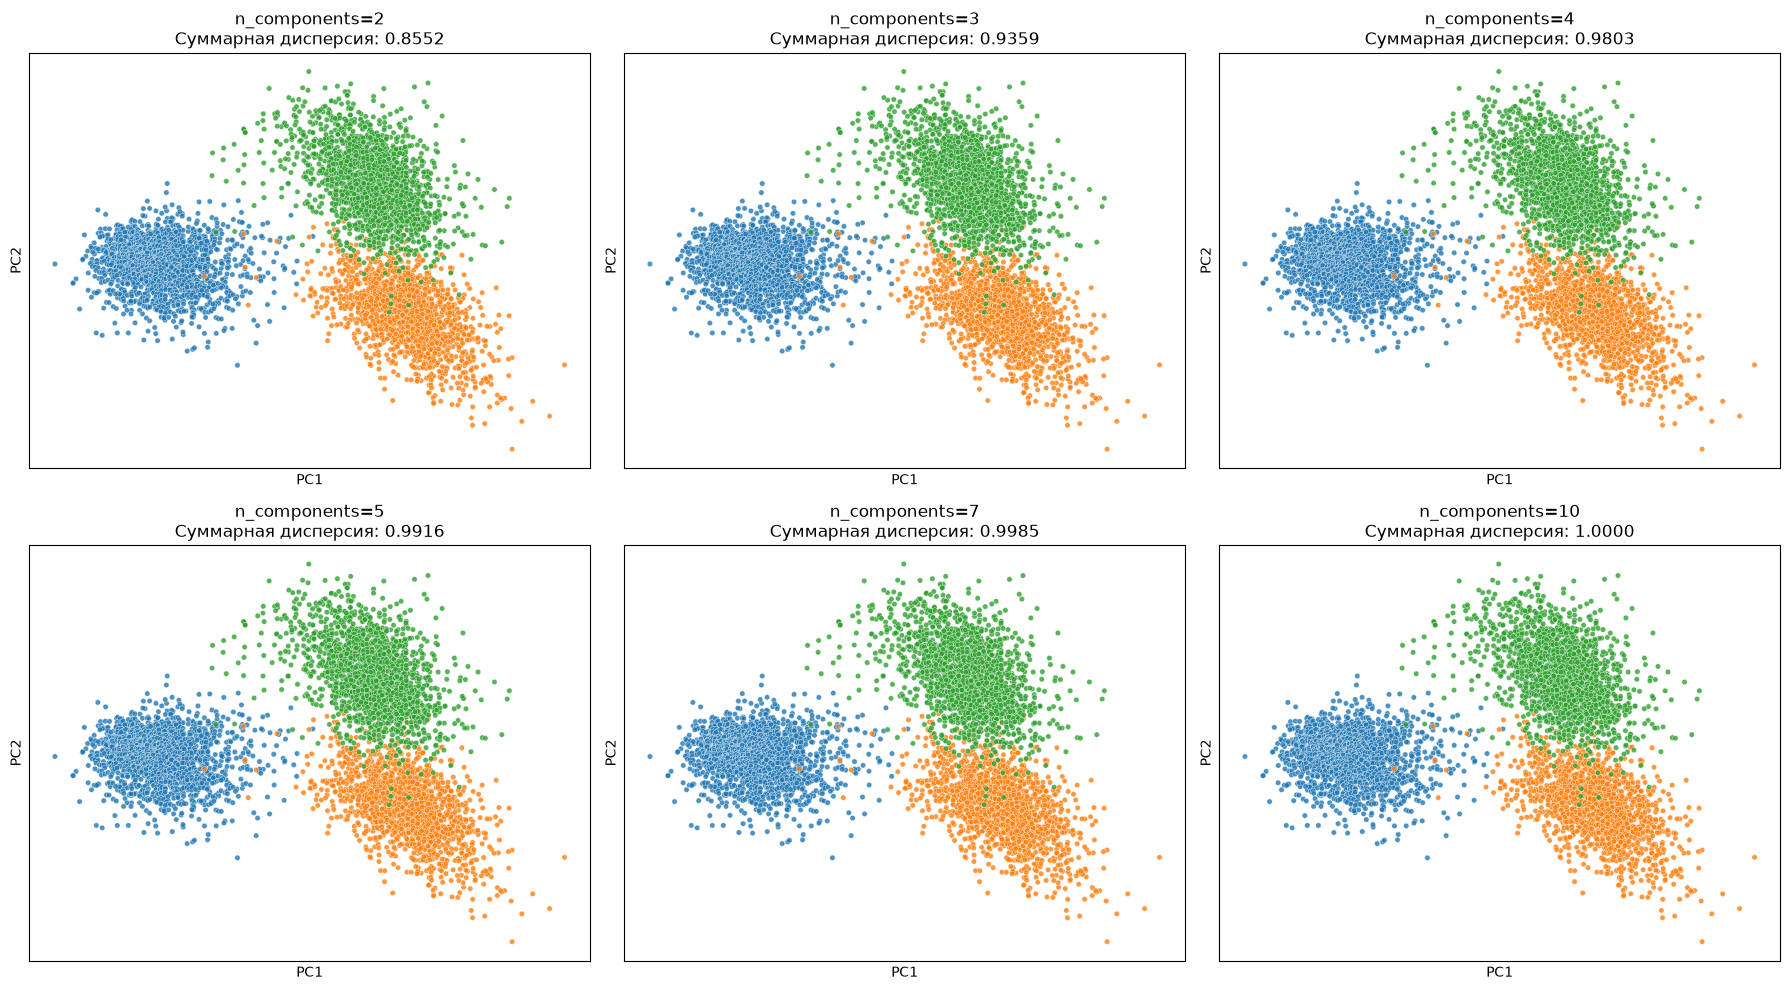

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, n in enumerate(n_components):
    pca = PCA(n_components=n, random_state=42)
    X_db_pca = pca.fit_transform(X_db_scaled)
    
    ax = axes[i]
    scatter = sns.scatterplot(
        x=X_db_pca[:, 0], y=X_db_pca[:, 1],
        hue=y_names, palette="tab10", s=15, ax=ax, legend=False, alpha=0.8
    )
    ax.set_title(f"n_components={n}\nСуммарная дисперсия: {pca.explained_variance_ratio_.sum():.4f}", fontsize=12)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

При разных n_components первые две компоненты остаются близкими, а общая структура мало меняется.

In [38]:
print("Digits")

pca_10 = PCA(n_components=10, random_state=42)
X_pca_10 = pca_10.fit_transform(X_scaled)

print("Суммарная объяснённая дисперсия (10 компонент):",
      pca_10.explained_variance_ratio_.sum())

Digits
Суммарная объяснённая дисперсия (10 компонент): 0.58873755337303


In [39]:
print("Dry_Bean")

pca_10 = PCA(n_components=10, random_state=42)
X_db_pca_10 = pca_10.fit_transform(X_db_scaled)

print("Суммарная объяснённая дисперсия (10 компонент):",
      pca_10.explained_variance_ratio_.sum())

Dry_Bean
Суммарная объяснённая дисперсия (10 компонент): 0.9999733506893026
